# Text-to-SQL em português: fine-tuning de LLM com QLoRA (GPU)

Notebook para rodar no **Google Colab** (Ambiente de execução → Alterar tipo → **T4 GPU**).
Fluxo: verificar GPU → dataset → baseline → 4 treinos com parâmetros diferentes → avaliação → frontend.

## 1. Verificar a GPU (print exigido no CP)

In [65]:
%cd /content/text2sql-llm
!git pull

/content/text2sql-llm
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 6 (delta 4), reused 6 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 1.33 KiB | 273.00 KiB/s, done.
From https://github.com/palomari/text2sql-llm
   8152ea1..81674e3  main       -> origin/main
Updating 8152ea1..81674e3
Fast-forward
 notebooks/text2sql_colab.ipynb | 83 ++++++++++++++----------------------------
 src/app.py                     | 58 +++++++++++++++++------------
 2 files changed, 62 insertions(+), 79 deletions(-)


In [34]:
!nvidia-smi
import torch
print("CUDA disponível:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "| CUDA:", torch.version.cuda)

Tue Oct 13 21:46:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P0             28W /   70W |    2815MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Obter o código
Troque `SEU_USUARIO` pelo seu usuário do GitHub (o repositório precisa estar publicado).

In [4]:
GITHUB_REPO = "https://github.com/palomari/text2sql-llm.git"
!git clone {GITHUB_REPO}
%cd text2sql-llm

Cloning into 'text2sql-llm'...
remote: Enumerating objects: 73, done.
remote: Counting objects: 100% (73/73), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 73 (delta 35), reused 61 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (73/73), 143.29 KiB | 1.88 MiB/s, done.
Resolving deltas: 100% (35/35), done.
/content/text2sql-llm/text2sql-llm


In [58]:
!pip install -q -r requirements.txt

In [6]:
!python src/train.py --name teste --epochs 0.2

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 231.35it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 35177.40 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1620.93 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4662.22 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4263.62 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 5640.91 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 25593.75 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1491.36 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4322.17 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 3943.94 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5906.21 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

## 3. Criar banco e dataset

In [7]:
!python src/make_dataset.py
!head -n 3 data/train.jsonl

train: 1142 exemplos
val: 125 exemplos
test: 233 exemplos
SQL do teste inéditas no treino: 193/233
{"question": "Quais os 7 produtos mais caros", "sql": "SELECT nome, preco FROM produtos ORDER BY preco DESC LIMIT 7"}
{"question": "Quais produtos custam mais de 800 reais?", "sql": "SELECT nome, preco FROM produtos WHERE preco > 800"}
{"question": "Pode me dizer? Conte os produtos agrupados por categoria.", "sql": "SELECT categoria, COUNT(*) FROM produtos GROUP BY categoria"}


## 4. Baseline: modelo SEM fine-tuning

In [8]:
!python src/evaluate_model.py --name baseline

Loading weights: 100% 338/338 [00:01<00:00, 230.92it/s]
{
  "run": "baseline",
  "n": 233,
  "exec_accuracy": 0.4893,
  "sql_valida": 0.7511,
  "exact_match": 0.2446,
  "exec_acc_sql_inedita": 0.4663,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}


## 5. Experimentos com parâmetros diferentes
Cada execução muda **um** parâmetro em relação à `run1`. Os resultados vão para `results/experimentos.csv`.

In [9]:
!python src/train.py --name run1 --r 8  --lr 2e-4 --epochs 3

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 233.13it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 32325.72 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1633.42 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4718.66 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4173.39 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 5997.02 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 25585.01 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1518.25 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4271.53 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 3951.22 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5867.08 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

In [10]:
!python src/train.py --name run2 --r 16 --lr 2e-4 --epochs 3

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 225.23it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 33142.56 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1606.87 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4526.36 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4185.86 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 6088.82 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 25668.94 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1533.40 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4357.41 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 4000.21 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5849.01 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

In [11]:
!python src/train.py --name run3 --r 8  --lr 1e-4 --epochs 3

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 225.54it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 30128.35 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1460.26 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4642.24 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4090.37 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 5946.41 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 25292.49 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1506.38 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4236.74 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 3999.94 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5875.43 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

In [12]:
!python src/train.py --name run4 --r 8  --lr 2e-4 --epochs 5

GPU: Tesla T4
Precisão: fp16 | compute capability: (7, 5)
Loading weights: 100% 338/338 [00:01<00:00, 226.79it/s]
Adding EOS to train dataset: 100% 1142/1142 [00:00<00:00, 34049.61 examples/s]
Tokenizing train dataset: 100% 1142/1142 [00:00<00:00, 1537.96 examples/s]
Building labels for train dataset: 100% 1142/1142 [00:00<00:00, 4695.69 examples/s]
Truncating train dataset: 100% 1142/1142 [00:00<00:00, 4173.06 examples/s]
Dropping fully masked examples from train dataset: 100% 1142/1142 [00:00<00:00, 6166.71 examples/s]
Adding EOS to eval dataset: 100% 125/125 [00:00<00:00, 23103.51 examples/s]
Tokenizing eval dataset: 100% 125/125 [00:00<00:00, 1495.93 examples/s]
Building labels for eval dataset: 100% 125/125 [00:00<00:00, 4338.48 examples/s]
Truncating eval dataset: 100% 125/125 [00:00<00:00, 4025.03 examples/s]
Dropping fully masked examples from eval dataset: 100% 125/125 [00:00<00:00, 5952.27 examples/s]
Parâmetros treináveis convertidos para fp32: 392
Dtypes treináveis: {'torch

## 6. Avaliar cada execução no conjunto de teste

In [13]:
for r in ["run1", "run2", "run3", "run4"]:
    !python src/evaluate_model.py --name {r} --adapter outputs/{r}/final

Loading weights: 100% 338/338 [00:01<00:00, 232.25it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 236.12it/s]
{
  "run": "run2",
  "n": 233,
  "exec_accuracy": 0.9957,
  "sql_valida": 1.0,
  "exact_match": 0.9957,
  "exec_acc_sql_inedita": 0.9948,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 231.47it/s]
{
  "run": "run3",
  "n": 233,
  "exec_accuracy": 0.9914,
  "sql_valida": 1.0,
  "exact_match": 0.9914,
  "exec_acc_sql_inedita": 0.9896,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 234.22it/s]
{
  "run": "run4",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_

## 7. Parâmetros de inferência (temperature) na melhor execução
Troque `run1` pela melhor execução.

In [14]:
BEST = "run1"
for t in [0.0, 0.3, 0.7, 1.0]:
    !python src/evaluate_model.py --name {BEST} --adapter outputs/{BEST}/final --temperature {t}

Loading weights: 100% 338/338 [00:01<00:00, 236.13it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.0,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 230.43it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 1.0,
  "sql_valida": 1.0,
  "exact_match": 1.0,
  "exec_acc_sql_inedita": 1.0,
  "n_sql_inedita": 193,
  "temperature": 0.3,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 229.23it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 0.9957,
  "sql_valida": 1.0,
  "exact_match": 0.9957,
  "exec_acc_sql_inedita": 0.9948,
  "n_sql_inedita": 193,
  "temperature": 0.7,
  "top_p": 0.9
}
Loading weights: 100% 338/338 [00:01<00:00, 229.13it/s]
{
  "run": "run1",
  "n": 233,
  "exec_accuracy": 0.9957,
  "sql_valida": 1.0,
  "exact_match": 0.9957,
  "exec_acc_sql_inedita": 0.9948,
  "n_sql_inedita": 193,
  "temperature": 1.0,
  "top_

## 8. Tabelas e gráfico

,run,lora_r,lr,epochs,val_loss,exec_accuracy,exec_acc_sql_inedita,sql_valida,exact_match,tempo_min,vram_pico_gb
0,baseline,NaN,NaN,NaN,NaN,0.4893,0.4663,0.7511,0.2446,NaN,NaN
1,run2,16.0,0.0002,3.0,0.0520,0.9957,0.9948,1.0000,0.9957,13.0,1.60
2,run3,8.0,0.0001,3.0,0.0580,0.9914,0.9896,1.0000,0.9914,12.9,1.46
3,run4,8.0,0.0002,5.0,0.0531,1.0000,1.0000,1.0000,1.0000,21.5,1.46
4,run1,8.0,0.0002,3.0,0.0528,1.0000,1.0000,1.0000,1.0000,12.9,1.46


,run,temperature,top_p,exec_accuracy,sql_valida,exec_acc_sql_inedita
5,run1,0.0,0.9,1.0000,1.0,1.0000
6,run1,0.3,0.9,1.0000,1.0,1.0000
7,run1,0.7,0.9,0.9957,1.0,0.9948
8,run1,1.0,0.9,0.9957,1.0,0.9948


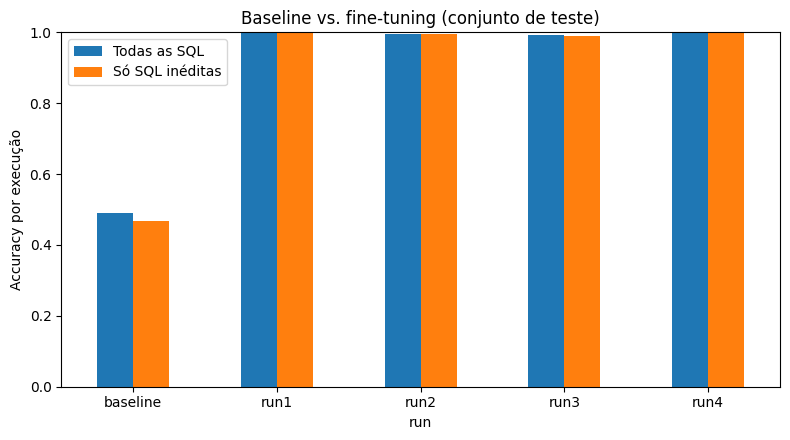

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

BEST = "run1"   # troque pela melhor execução

exp = pd.read_csv("results/experimentos.csv")
exp = exp[exp.run != "teste"].drop_duplicates("run", keep="last")

av = pd.read_csv("results/avaliacao.csv")
av = av[av.run != "teste"].drop_duplicates(["run", "temperature"], keep="last")

# Tabela principal: baseline e execuções, com temperature 0.0
base = av[av.temperature == 0.0]
tabela = base.merge(exp, on="run", how="left")
cols = ["run", "lora_r", "lr", "epochs", "val_loss", "exec_accuracy",
        "exec_acc_sql_inedita", "sql_valida", "exact_match", "tempo_min", "vram_pico_gb"]
tabela = tabela[cols]
display(tabela)

# Parâmetros de inferência na melhor execução
temps = av[av.run == BEST][["run", "temperature", "top_p", "exec_accuracy",
                            "sql_valida", "exec_acc_sql_inedita"]].sort_values("temperature")
display(temps)

# Gráfico: baseline x execuções
ordem = ["baseline"] + sorted(r for r in base.run if r != "baseline")
t = tabela.set_index("run").reindex(ordem)
ax = t[["exec_accuracy", "exec_acc_sql_inedita"]].plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy por execução")
ax.set_title("Baseline vs. fine-tuning (conjunto de teste)")
ax.legend(["Todas as SQL", "Só SQL inéditas"])
plt.tight_layout()
plt.savefig("results/comparacao.png", dpi=150)
plt.show()

## 9. Exemplos qualitativos (baseline x fine-tuned)

In [16]:
import json
base = json.load(open("results/pred_baseline_T0.0.json", encoding="utf-8"))
ft = json.load(open(f"results/pred_{BEST}_T0.0.json", encoding="utf-8"))
for b, f in list(zip(base, ft))[:8]:
    print("Pergunta :", b["question"])
    print("Esperada :", b["gold_sql"])
    print("Baseline :", b["pred_sql"], "->", "OK" if b["correto"] else "ERRO")
    print("Fine-tune:", f["pred_sql"], "->", "OK" if f["correto"] else "ERRO")
    print("-" * 80)

Pergunta : Gostaria de saber: Qual o número de pedidos de agosto/2025?
Esperada : SELECT COUNT(*) FROM pedidos WHERE strftime('%Y-%m', data_pedido) = '2025-08'
Baseline : SELECT COUNT(id) FROM pedidos WHERE strftime('%Y-%m', data_pedido) = '2025-08' -> OK
Fine-tune: SELECT COUNT(*) FROM pedidos WHERE strftime('%Y-%m', data_pedido) = '2025-08' -> OK
--------------------------------------------------------------------------------
Pergunta : Pode me dizer? Liste os 8 produtos com maior preço.
Esperada : SELECT nome, preco FROM produtos ORDER BY preco DESC LIMIT 8
Baseline : SELECT nome FROM produtos ORDER BY preco DESC LIMIT 8 -> ERRO
Fine-tune: SELECT nome, preco FROM produtos ORDER BY preco DESC LIMIT 8 -> OK
--------------------------------------------------------------------------------
Pergunta : por favor, quantos pedidos estão enviados?
Esperada : SELECT COUNT(*) FROM pedidos WHERE status = 'enviado'
Baseline : SELECT COUNT(*) FROM pedidos WHERE status = 'enviado' -> OK
Fine-tune: 

## 10. Frontend (Gradio)
Gera um link público temporário. Tire o print do frontend funcionando.

In [ ]:
%cd /content/text2sql-llm
!python src/app.py --demo --share

/content/text2sql-llm
* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://f5b966585d7fdb740e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


: 

In [59]:
import subprocess, os
os.makedirs("results", exist_ok=True)
p = subprocess.Popen("python src/train.py --name run1 --r 8 --lr 2e-4 --epochs 3 > results/run1_treino.log 2>&1", shell=True)

In [60]:
p.wait()

0

In [61]:
!ls outputs/run1/final

adapter_config.json	   README.md		  training_args.bin
adapter_model.safetensors  tokenizer_config.json
chat_template.jinja	   tokenizer.json


In [62]:
import subprocess
p3 = subprocess.Popen("python src/app.py --adapter outputs/run1/final --share > results/front.log 2>&1", shell=True)

In [63]:
!tail -n 5 results/front.log

Loading weights: 100%|██████████| 338/338 [00:01<00:00, 229.59it/s]


In [1]:
import subprocess, time, re

# 1) encerra os fronts antigos (sem matar o kernel)
subprocess.run(["pkill", "-f", "src/app.py"])
time.sleep(3)

# 2) sobe um front novo, só com o adaptador run1
p3 = subprocess.Popen("exec python -u src/app.py --adapter outputs/run1/final --share > results/front.log 2>&1", shell=True)

# 3) espera o link (ou mostra o erro)
link = None
for _ in range(72):                      # até cerca de 6 minutos
    txt = open("results/front.log", errors="ignore").read()
    m = re.search(r"https://\S+\.gradio\.live", txt)
    if m:
        link = m.group(0)
        break
    if p3.poll() is not None:            # o processo terminou antes de ter link
        break
    time.sleep(5)

if link:
    print("LINK DO FRONT:", link)
else:
    print("Sem link. Processo ainda ativo:", p3.poll() is None, "| código de saída:", p3.poll())
    print(open("results/front.log", errors="ignore").read()[-2000:])
    print(subprocess.run("free -h", shell=True, capture_output=True, text=True).stdout)

FileNotFoundError: [Errno 2] No such file or directory: 'results/front.log'

## 11. Salvar resultados no Google Drive (a sessão do Colab é temporária)

In [56]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/text2sql-llm
!cp -r results outputs /content/drive/MyDrive/text2sql-llm/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
